# 03. Fair Value Calibration, Stationarity & Drift Detrending

We classify the underlying stochastic dynamics of Round 0 and Round 1 instruments strictly on calibration splits (`Day -2` & `Day -1`) before checking consistency on held-out `Day 0`:
1. **Stationarity**: Augmented Dickey-Fuller (ADF) unit-root test with constant.
2. **Mean-Reverting Assets (`ASH_COATED_OSMIUM`)**: Exact discrete AR(1) $\to$ continuous Ornstein-Uhlenbeck (OU) mapping:
   $$d FV_t = \theta(\mu - FV_t)\,dt + \sigma\,d W_t$$
3. **Drifting Assets (`INTARIAN_PEPPER_ROOT`)**: Linear drift OLS ($P_t = \alpha + \beta t + \varepsilon_t$) and stationarity diagnostics on detrended residuals.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from prosperity_toolkit.analysis import (
    augmented_dickey_fuller_test,
    estimate_linear_drift,
    estimate_ou_ar1,
    extract_two_sided_mid,
)
from prosperity_toolkit.data.loader import DataLoader

loader = DataLoader(data_root=root / "data")
calib_rows = []
for day in (-2, -1, 0):
    df = loader.load_day_prices(1, day)
    for sym in ("ASH_COATED_OSMIUM", "INTARIAN_PEPPER_ROOT"):
        mid = extract_two_sided_mid(df, sym)
        vals = mid.to_numpy(dtype=float)
        ts = mid.index.to_numpy(dtype=float)
        adf = augmented_dickey_fuller_test(vals, lags=2)
        ou = estimate_ou_ar1(vals, dt=1.0)
        slope, intercept, r2 = estimate_linear_drift(ts, vals)
        calib_rows.append({
            "split": "OOS" if day == 0 else "IS",
            "day": day,
            "symbol": sym,
            "adf_t": round(adf.t_statistic, 3),
            "reject_unit_root": adf.reject_unit_root_5pct,
            "ou_mu": round(ou.mu, 2),
            "ou_theta": round(ou.theta, 4),
            "half_life": round(ou.half_life, 2) if ou.half_life < 1e4 else "inf",
            "drift_per_step": round(slope * 100.0, 5),
            "r2_linear": round(r2, 4),
        })

pd.DataFrame(calib_rows)

,split,day,symbol,adf_t,reject_unit_root,ou_mu,ou_theta,half_life,drift_per_step,r2_linear
0,IS,-2,ASH_COATED_OSMIUM,-8.429,True,9998.15,0.0853,8.13,-0.00013,0.0062
1,IS,-2,INTARIAN_PEPPER_ROOT,-0.094,False,17402.28,0.0000,inf,0.10000,1.0000
2,IS,-1,ASH_COATED_OSMIUM,-10.990,True,10000.84,0.1352,5.13,-0.00008,0.0036
3,IS,-1,INTARIAN_PEPPER_ROOT,-0.200,False,16172.81,0.0000,inf,0.10001,1.0000
4,OOS,0,ASH_COATED_OSMIUM,-7.898,True,10001.63,0.0732,9.47,0.00015,0.0067
5,OOS,0,INTARIAN_PEPPER_ROOT,-0.205,False,17129.85,0.0000,inf,0.10000,1.0000


## 1. Detrending `INTARIAN_PEPPER_ROOT` & Visualizing Stationary Excursions

Detrended PEPPER Day -2 residuals: std=1.1237, ADF_t=-55.50


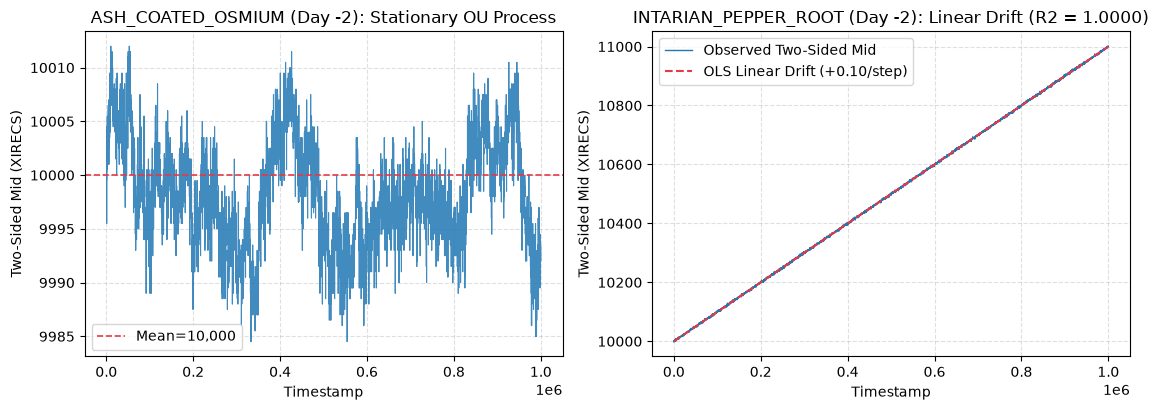

In [2]:
df_d2 = loader.load_day_prices(1, -2)
osmium = extract_two_sided_mid(df_d2, "ASH_COATED_OSMIUM")
pepper = extract_two_sided_mid(df_d2, "INTARIAN_PEPPER_ROOT")
ts = pepper.index.to_numpy(dtype=float)
p_vals = pepper.to_numpy(dtype=float)
slope, intercept, _ = estimate_linear_drift(ts, p_vals)
pepper_resid = p_vals - (intercept + slope * ts)
resid_adf = augmented_dickey_fuller_test(pepper_resid, lags=2)
print(f"Detrended PEPPER Day -2 residuals: std={np.std(pepper_resid, ddof=1):.4f}, ADF_t={resid_adf.t_statistic:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].plot(osmium.index, osmium.values, linewidth=0.8, alpha=0.85)
axes[0].axhline(10000.0, color="#e63946", linestyle="--", linewidth=1.2, label="Mean=10,000")
axes[0].set_title("ASH_COATED_OSMIUM (Day -2): Stationary OU Process")
axes[0].set_xlabel("Timestamp")
axes[0].set_ylabel("Two-Sided Mid (XIRECS)")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

axes[1].plot(ts, p_vals, label="Observed Two-Sided Mid", linewidth=1.0)
axes[1].plot(ts, intercept + slope * ts, color="#e63946", linestyle="--", label="OLS Linear Drift (+0.10/step)")
axes[1].set_title("INTARIAN_PEPPER_ROOT (Day -2): Linear Drift (R2 = 1.0000)")
axes[1].set_xlabel("Timestamp")
axes[1].set_ylabel("Two-Sided Mid (XIRECS)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

fig.tight_layout()
plt.show()